# Elección de destino: permitir que cada bloque elija planta o botadero

**Pregunta:** ¿Cuándo forma parte de la decisión de programación el destino de un bloque, y qué valor aporta esa flexibilidad?

**Level**: 1

**Prerequisites**: topic 01, CPIT formulation and package setup

**Reading time**: 24 minutes

## Objetivos

Construye una instancia PCPSP con semilla mediante PhaseFlow, programa destinos con OreBlocks y reconcilia valor y uso de capacidad. Después distingue CPIT con destino fijo de la elección conjunta de período y destino. Las cifras se calculan desde cero para el caso sintético declarado.

This is a method lesson rather than a report of a baked trace. We rebuild one declared input, call public package methods in sequence, retain their returned arrays, and interpret a figure computed from those results. The exercise separates what the optimization model decides from what a visualization can show. The same cells are useful as a starting point for another small synthetic case, provided its dimensions, scenario, resource rows and destination economics are changed together.

## Preparación

Desde la raíz del repositorio, instala el entorno exacto fijado. Esta celda informa las versiones importadas. El notebook no instala paquetes durante la ejecución.

```bash
pip install oreblocks==0.6.3 numpy==2.5.1 scipy==1.18.1 matplotlib==3.11.2
```

In [1]:
# Importa el paquete fijado, las herramientas gráficas y el constructor de instancias de PhaseFlow.
import importlib.metadata as metadata
import json
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, str(Path('../../../data-pipeline').resolve()))
from pipeline.io.schema import Case, DepositSpec, Scenario
from pipeline.model.instances import build_instance
import oreblocks as ob
for package in ('oreblocks', 'numpy', 'scipy', 'matplotlib'):
    print(package, metadata.version(package))

oreblocks 0.6.3
numpy 2.5.1
scipy 1.18.1
matplotlib 3.11.2


## Datos

El ejemplo usa una veta sintética de 48 bloques, generada con semilla 31 por el constructor MIT de PhaseFlow y OreBlocks 0.6.3. El manifiesto twin-vein comprometido se consulta sólo como contexto de procedencia; el plan se calcula desde una reconstrucción explícita del caso. MineLib no se usa: su resultado Newman1 es un agregado CPIT con destino fijo y condiciones académicas de descarga, no datos redistribuibles por bloque ni un comparador PCPSP.

Reconstruiremos el caso docente documentado en vez de copiar su traza como resultado. La semilla 31 fija el depósito generado. El manifiesto `data/derived/manifests/twin-vein.json` conserva el escenario y los métodos comprometidos; los arreglos de bloques se generan nuevamente mediante el pipeline. Las fuentes tienen roles distintos: el manifiesto aporta procedencia y el generador con semilla es la entrada experimental. A deterministic seed supports repeatability, not geological truth. The small case is deliberately used to make destination alternatives and period assignments inspectable. The code below rebuilds exactly the dimensions and scenario stated here; when experimenting, alter the seed explicitly and record every changed capacity or economic assumption.

Build the input through PhaseFlow's typed `Case` and `Scenario` contract. The two resource rows represent mining and processing; their fractions are capacity assumptions, not measured plant limits. We inspect the contract report before passing the instance to the scheduling methods.

In [2]:
# Reconstruye la instancia docente con semilla y lee el registro de procedencia comprometido.
case = Case(
    id='nb-destination-vein-4x4x3', category='teaching',
    title_en='Destination lesson', title_es='Leccion de destinos',
    deposit=DepositSpec(kind='twin', archetype='vein', dims=(4, 4, 3), seed=31),
    scenario=Scenario(periods=4, discount_rate=0.08,
                      capacity_fraction=(0.70, 0.50),
                      resource_names=('extraccion', 'procesamiento')),
)
instance = build_instance(case)
manifest = json.loads(Path('../../../data/derived/manifests/twin-vein.json').read_text(encoding='utf-8'))
print('contrato aceptado:', instance.report.ok)
print('bloques:', instance.n_blocks, '| recursos:', instance.pcpsp.n_resources,
      '| destinos:', instance.pcpsp.n_destinations)
print('caso de procedencia comprometido:', manifest['case_id'])

contrato aceptado: True
bloques: 48 | recursos: 2 | destinos: 2
caso de procedencia comprometido: twin-vein


## Método

Un modelo con destinos asigna período y destino en conjunto. Cada bloque extraído consume los coeficientes de su alternativa; cada bloque no extraído no consume recursos ni aporta valor. El objetivo descuenta el valor del destino según el período. La secuencia de cómputo separa cota, plan constructivo y puntuación para distinguir una cota superior de un resultado factible.

El modelo que elige destinos representa un problema distinto de CPIT. En CPIT cada bloque tiene un valor y un vector de recursos fijos antes de programarlo. En PCPSP el bloque puede asignarse a destinos como planta o botadero, y tanto su valor como su consumo de recursos dependen de esa elección. Un bloque enviado a planta consume capacidad de procesamiento; el mismo bloque enviado a botadero consume capacidad de extracción, pero no de procesamiento. El planificador debe decidir cuándo extraerlo y a dónde enviarlo.

Esta diferencia importa sobre todo cuando existen límites de capacidad. Un bloque de alta ley puede tener valor de procesamiento, pero la planta podría estar llena cuando sus predecesores habilitan su extracción. Enviar un bloque marginal a botadero puede reservar capacidad de planta para mineral más valioso. También puede ser conveniente esperar un período si el valor descontado en planta supera el valor de enviarlo ahora a botadero. La elección de destino modifica en conjunto el orden, el período y los coeficientes; no es una etiqueta añadida después de resolver CPIT.

PhaseFlow construye una instancia sintética con dos destinos a partir de la misma veta pequeña con semilla que usa la lección introductoria. OreBlocks genera el depósito, la precedencia de taludes, las capacidades y el campo de leyes mediante el constructor de instancias de PhaseFlow. El caso permite observar conteos y filas de recursos, pero es evidencia sintética. No constituye un diseño de producción ni aporta una economía de destinos calibrada con datos de terreno.

Primero pedimos al paquete la relajación continua de PCPSP. Su objetivo es una cota superior porque reemplazar las decisiones binarias de período y destino por fracciones amplía la región factible. Luego ejecutamos TopoSort con elección de destino: recorre un orden topológico ponderado y selecciona el destino factible y el período factible más temprano para cada bloque. El paquete devuelve los arreglos de período y destino, el NPV y el uso de recursos por período. Recalcular el valor con el evaluador público es una reconciliación independiente, no otro optimizador.

Un plan factible se revisa período por período. En cada fila de recursos, el uso debe permanecer bajo el límite declarado. En cada arco de precedencia, un bloque no puede aparecer antes que su predecesor. El paquete construye factibilidad de recursos al ubicar los bloques, y el evaluador rechaza un bloque extraído sin destino válido. Estas verificaciones prueban factibilidad para el modelo codificado; no prueban optimalidad, no validan los supuestos económicos ni demuestran que una mina real pueda operar el plan.

Lee el resultado como una comparación de decisiones bajo un único escenario declarado. Los conteos planta/botadero muestran cuántos bloques usan cada alternativa; el NPV representa su aporte descontado. Ningún conteo por sí solo identifica el valor económico de la flexibilidad: enviar un bloque a botadero puede habilitar otro bloque de planta más valioso, y un bloque no extraído no aporta valor al plan. La cota, el resultado factible y la brecha se interpretan juntos. La brecha mide distancia a la relajación, no certifica optimalidad entera.

Los valores graficados por período muestran dónde el plan utiliza las capacidades de extracción y procesamiento. Una barra bajo el límite indica capacidad sobrante en ese período, pero no que agregar capacidad mejore el plan global. La figura tampoco contiene los arcos de precedencia ni incertidumbre geológica. Es un diagnóstico de una programación y el número debe acompañarse de sus entradas, factibilidad y cota de relajación.

La lección termina en un modelo pequeño con dos destinos. Los casos de PhaseFlow incluyen agregados publicados y gemelos sintéticos, pero el registro de Newman1 de MineLib es un resultado CPIT con destino fijo, no un benchmark de destinos. No compares su objetivo con el de este PCPSP como si fueran la misma formulación. El artículo de destinos de Referencias aporta contexto científico; aquí ejecutamos la implementación de OreBlocks en un caso sintético explícito.

Step 1 computes the continuous PCPSP upper bound. Keep the formulation label beside the value: it bounds a schedule that may choose destinations, not an unrelated CPIT run. The small model fits the direct LP row budget; the status and matrix dimensions are useful checks when scaling the example.

In [3]:
# Resuelve la relajación PCPSP para acotar cada programación factible.
relaxation = ob.pcpsp_lp_bound(instance.pcpsp, instance.precedence,
                                max_rows=1500000, time_limit=20,
                                solution=True)
print('estado del LP:', relaxation.status)
print('variables:', relaxation.n_variables, '| filas:', relaxation.n_rows)
print('cota superior PCPSP:', round(relaxation.bound, 2))

estado del LP: optimal
variables: 576 | filas: 1144
cota superior PCPSP: 311484.31


Step 2 constructs a destination-aware plan. The package checks prerequisite availability, then tests the remaining capacity for each destination and period. Its choices are returned as arrays so we can inspect the method's decisions instead of accepting only a headline NPV.

In [4]:
# Construye un plan factible con elecciones conjuntas de período y destino.
destination_plan = ob.destination_toposort(instance.pcpsp,
                                             instance.precedence)
print('metodo:', destination_plan.method)
print('NPV:', round(destination_plan.npv, 2))
print('bloques extraidos:', destination_plan.mined_blocks)

metodo: pcpsp-destination-toposort
NPV: 179593.14
bloques extraidos: 16


Step 3 independently scores the returned arrays. This is important because a schedule value depends on the chosen destination as well as the period. The capacity matrix is reported by resource and period; comparing it with the declared limits reveals both binding periods and spare capacity.

In [5]:
# Recalcula valor y uso de recursos desde los dos arreglos de decisión.
scored_npv, resource_use = ob.pcpsp_schedule_value(
    instance.pcpsp, destination_plan.period_of_block,
    destination_plan.destination_of_block)
plant = int(np.sum(destination_plan.destination_of_block == 1))
waste = int(np.sum(destination_plan.destination_of_block == 0))
print('NPV recalculado:', round(scored_npv, 2))
print('bloques a planta:', plant, '| bloques a estéril:', waste)
print('uso de recursos por periodo:', np.round(resource_use, 1))
print('limites de recursos:', np.round(instance.pcpsp.limit, 1))

NPV recalculado: 179593.14
bloques a planta: 8 | bloques a estéril: 8
uso de recursos por periodo: [[10800. 10800. 10800. 10800.]
 [ 5400.  5400.  5400.  5400.]]
limites de recursos: [[13230. 13230. 13230. 13230.]
 [ 6075.  6075.  6075.  6075.]]


The chart turns the returned schedules into a period-by-period diagnostic. The horizontal guides are the declared resource limits. Mining and processing remain separate units; counts of blocks are not tonnes. The code uses package-scored resource arrays rather than recomputing coefficients in the notebook.

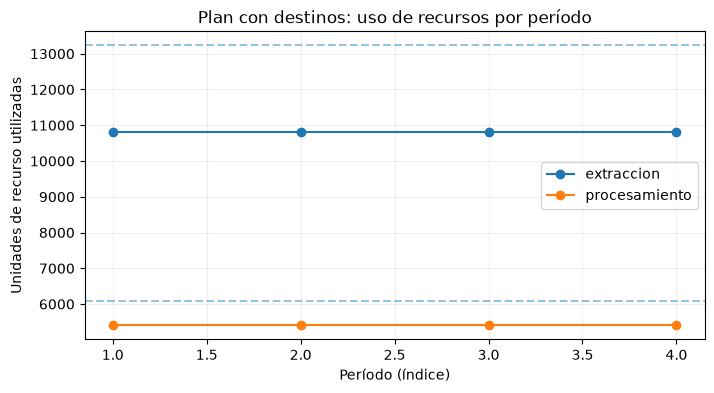

In [6]:
# Grafica uso de capacidad informado por el paquete con unidades explícitas.
fig, ax = plt.subplots(figsize=(8, 4))
periods = np.arange(1, instance.pcpsp.n_periods + 1)
for resource, label in enumerate(instance.cpit.resource_names):
    ax.plot(periods, resource_use[resource], marker='o', label=label)
    ax.axhline(instance.pcpsp.limit[resource, 0], linestyle='--', alpha=0.45)
ax.set(title='Plan con destinos: uso de recursos por período',
       xlabel='Período (índice)', ylabel='Unidades de recurso utilizadas')
ax.legend()
ax.grid(alpha=0.2)
plt.show()

The lines show whether the constructed schedule approaches its mining and processing limits in each period; dashed guides mark those declared capacities. A line below its guide indicates unused capacity for this schedule, not proof that relaxing that row has no value. This plot omits block precedence, discounting and destination-specific cash flows, so it is a resource diagnostic rather than a full plan evaluation. The next output reports both destination counts and the independently recomputed objective.

## Resultados

**Respuesta:** TopoSort con destinos asigna 8 bloques a planta y 8 a botadero, con NPV recalculado de 179593.14; la relajación LP PCPSP dio 311484.31. La figura de valor y uso por período muestra cómo las alternativas elegidas consumen capacidad. Es un plan factible para un caso docente con semilla, no un plan de faena ni una prueba de optimalidad entera.

Usa los valores impresos y el uso por período para comprobar si coinciden el objeto de método y el evaluador independiente. El objetivo LP acota el mismo modelo con elección de destino, mientras los conteos describen asignaciones y no toneladas. Estos resultados corresponden a semilla 31 y cuatro períodos; no se transfieren a otra economía minera.

In [7]:
# Agrupa los valores calculados que responden la pregunta del notebook.
print(f'plant={plant}; waste={waste}; npv={scored_npv:.2f}; bound={relaxation.bound:.2f}')

plant=8; waste=8; npv=179593.14; bound=311484.31


## Resumen

La elección de destino acopla el período con los arreglos de valor y recursos. El paquete programa cada bloque y puntúa el plan; la relajación da una cota superior de referencia. La figura describe el caso sintético y no respalda un corte universal ni una recomendación operacional.

## Referencias

- Jelvez, Morales y Nancel-Penard (2018), programación de rajos con destinos: https://www.delphoslab.cl/Publicaciones/2018/Jelvez_et_al_MPES2018.pdf
- Constructor de instancias sintéticas y pipeline de PhaseFlow: https://github.com/fsantibanezleal/CAOS_PhaseFlow
- Dossier PhaseFlow: docs/methodologies/09_destinations.md